<a href="https://colab.research.google.com/github/MoSibai2/ecommerce-sales-analysis/blob/main/ecommerce_sales_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Brazilian E-Commerce Sales Analysis

## Project Overview

This project analyzes the Brazilian E-Commerce Public Dataset by Olist to uncover business insights related to sales performance, product categories, payment methods, customer satisfaction, and delivery performance.

## Project Objectives

- Analyze overall sales and revenue performance.
- Identify top-performing product categories.
- Examine customer payment preferences.
- Evaluate customer satisfaction through review scores.
- Analyze delivery performance and identify potential delays.

## Dataset

Brazilian E-Commerce Public Dataset by Olist (2016–2018).

## Tools & Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Google Colab

## Analysis Scope

The analysis focuses primarily on delivered orders to evaluate completed transactions and customer experiences.

# Table of Contents

1. Data Loading
2. Initial Data Exploration
3. Data Cleaning and Preparation
4. Order Status Analysis
5. Delivery Performance Analysis
6. Sales and Revenue Analysis
7. Product Category Analysis
8. Payment Method Analysis
9. Customer Review Analysis
10. Visualizations
11. Final Business Insights
12. Business Recommendations
13. Project Limitations

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("E-Commerce Sales Analysis")
print("Libraries imported successfully!")

E-Commerce Sales Analysis
Libraries imported successfully!


In [2]:
import zipfile
import os

zip_path = "/content/archive.zip"
extract_path = "/content/olist_data"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

files = os.listdir(extract_path)

print("Number of files:", len(files))
print("\nFiles found:")
for file in files:
    print(file)

Number of files: 9

Files found:
olist_geolocation_dataset.csv
olist_orders_dataset.csv
olist_order_items_dataset.csv
olist_customers_dataset.csv
olist_sellers_dataset.csv
olist_order_reviews_dataset.csv
product_category_name_translation.csv
olist_order_payments_dataset.csv
olist_products_dataset.csv


In [3]:
import pandas as pd
import os

data_path = "/content/olist_data"

datasets = {}

for file in os.listdir(data_path):
    if file.endswith(".csv"):
        name = file.replace(".csv", "")
        datasets[name] = pd.read_csv(os.path.join(data_path, file))

for name, df in datasets.items():
    print(f"\n{'='*50}")
    print(f"Dataset: {name}")
    print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print("Columns:", list(df.columns))


Dataset: olist_geolocation_dataset
Rows: 1,000,163 | Columns: 5
Missing values: 0
Duplicate rows: 261831
Columns: ['geolocation_zip_code_prefix', 'geolocation_lat', 'geolocation_lng', 'geolocation_city', 'geolocation_state']

Dataset: olist_orders_dataset
Rows: 99,441 | Columns: 8
Missing values: 4908
Duplicate rows: 0
Columns: ['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Dataset: olist_order_items_dataset
Rows: 112,650 | Columns: 7
Missing values: 0
Duplicate rows: 0
Columns: ['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value']

Dataset: olist_customers_dataset
Rows: 99,441 | Columns: 5
Missing values: 0
Duplicate rows: 0
Columns: ['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

Dataset: olist_sellers_dataset
Rows: 3,095 | Columns: 4
M

In [4]:
# Missing values analysis
for name, df in datasets.items():
    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if not missing.empty:
        print(f"\n{name}")
        print(missing.sort_values(ascending=False))

# Geolocation duplicate analysis
geo = datasets["olist_geolocation_dataset"]

print("\nGeolocation duplicate analysis")
print("Exact duplicate rows:", geo.duplicated().sum())

print(
    "Duplicate ZIP code prefixes:",
    geo["geolocation_zip_code_prefix"].duplicated().sum()
)


olist_orders_dataset
order_delivered_customer_date    2965
order_delivered_carrier_date     1783
order_approved_at                 160
dtype: int64

olist_order_reviews_dataset
review_comment_title      87656
review_comment_message    58247
dtype: int64

olist_products_dataset
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Geolocation duplicate analysis
Exact duplicate rows: 261831
Duplicate ZIP code prefixes: 981148


In [5]:
orders = datasets["olist_orders_dataset"]

print("Order Status Distribution:")
print(orders["order_status"].value_counts())

print("\nMissing Dates by Order Status:")

date_columns = [
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date"
]

print(
    orders.groupby("order_status")[date_columns]
    .apply(lambda group: group.isnull().sum())
)

Order Status Distribution:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Missing Dates by Order Status:
              order_approved_at  order_delivered_carrier_date  \
order_status                                                    
approved                      0                             2   
canceled                    141                           550   
created                       5                             5   
delivered                    14                             2   
invoiced                      0                           314   
processing                    0                           301   
shipped                       0                             0   
unavailable                   0                           609   

              order_delivered_customer_date  
order_status                         

In [6]:
orders = datasets["olist_orders_dataset"]

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

print(orders[date_columns].dtypes)

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [7]:
print("Invalid or missing date values:")
print(orders[date_columns].isnull().sum())

Invalid or missing date values:
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


In [8]:
# Select delivered orders
delivered_orders = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].notna())
].copy()

# Calculate delivery time in days
delivered_orders["delivery_days"] = (
    delivered_orders["order_delivered_customer_date"] -
    delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Identify late deliveries
delivered_orders["is_late"] = (
    delivered_orders["order_delivered_customer_date"] >
    delivered_orders["order_estimated_delivery_date"]
)

# Calculate KPIs
total_delivered = len(delivered_orders)
late_orders = delivered_orders["is_late"].sum()
on_time_orders = total_delivered - late_orders

print("DELIVERY PERFORMANCE REPORT")
print("=" * 40)

print("Delivered orders analyzed:", total_delivered)

print(
    "Average delivery time:",
    round(delivered_orders["delivery_days"].mean(), 2),
    "days"
)

print(
    "Fastest delivery:",
    round(delivered_orders["delivery_days"].min(), 2),
    "days"
)

print(
    "Slowest delivery:",
    round(delivered_orders["delivery_days"].max(), 2),
    "days"
)

print("Late orders:", late_orders)

print("On-time orders:", on_time_orders)

print(
    "Late delivery rate:",
    round(late_orders / total_delivered * 100, 2),
    "%"
)

print(
    "On-time delivery rate:",
    round(on_time_orders / total_delivered * 100, 2),
    "%"
)

DELIVERY PERFORMANCE REPORT
Delivered orders analyzed: 96470
Average delivery time: 12.56 days
Fastest delivery: 0.53 days
Slowest delivery: 209.63 days
Late orders: 7826
On-time orders: 88644
Late delivery rate: 8.11 %
On-time delivery rate: 91.89 %


In [9]:
# Delivery time statistics
print("DELIVERY TIME DISTRIBUTION")
print("=" * 40)

print("Median:", round(delivered_orders["delivery_days"].median(), 2))
print("25th percentile:", round(delivered_orders["delivery_days"].quantile(0.25), 2))
print("75th percentile:", round(delivered_orders["delivery_days"].quantile(0.75), 2))
print("90th percentile:", round(delivered_orders["delivery_days"].quantile(0.90), 2))
print("95th percentile:", round(delivered_orders["delivery_days"].quantile(0.95), 2))
print("99th percentile:", round(delivered_orders["delivery_days"].quantile(0.99), 2))

print("\nNegative delivery durations:",
      (delivered_orders["delivery_days"] < 0).sum())

print("\n10 Longest Deliveries:")

print(
    delivered_orders[
        ["order_id", "delivery_days", "is_late"]
    ]
    .sort_values("delivery_days", ascending=False)
    .head(10)
)

DELIVERY TIME DISTRIBUTION
Median: 10.22
25th percentile: 6.77
75th percentile: 15.72
90th percentile: 23.1
95th percentile: 29.27
99th percentile: 46.05

Negative delivery durations: 0

10 Longest Deliveries:
                               order_id  delivery_days  is_late
19590  ca07593549f1816d26a572e06dc1eab6     209.628611     True
55619  1b3190b2dfa9d789e1f14c05b647a14a     208.351759     True
61610  440d0d17af552815d15a9e41abe49359     195.634016     True
70307  2fb597c2f772eca01b1f5c561bf6cc7b     194.850174     True
89130  285ab9426d6982034523a855f55a885e     194.633611     True
38509  0f4519c5f1c541ddec9f21b3bddd533a     194.049583     True
11399  47b40429ed8cce3aee9199792275433f     191.463542     True
81401  2fe324febf907e3ea3f2aa9650869fa5     189.863160     True
54480  2d7561026d542c8dbd8f0daeadf67a43     188.134618     True
68769  c27815f7e3dd0b926b58552628481575     187.743843     True


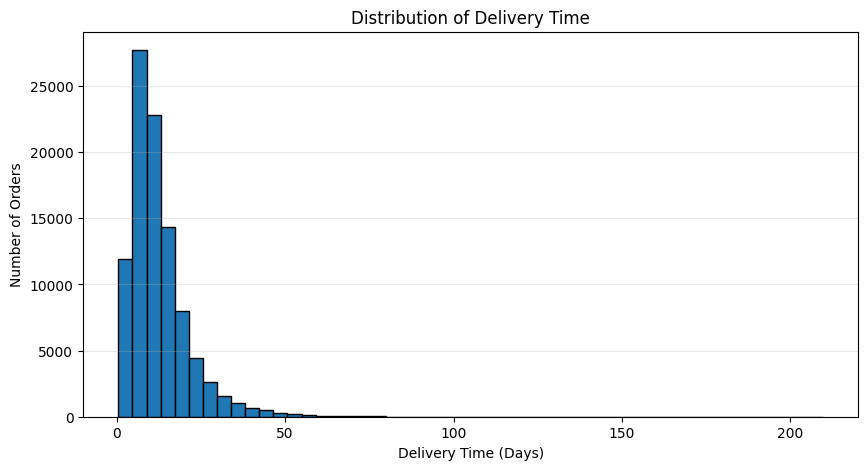

In [10]:
plt.figure(figsize=(10, 5))

plt.hist(
    delivered_orders["delivery_days"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [11]:
# Calculate delay in days
delivered_orders["delay_days"] = (
    delivered_orders["order_delivered_customer_date"] -
    delivered_orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Inspect the 10 longest deliveries
longest_orders = delivered_orders.sort_values(
    "delivery_days", ascending=False
).head(10)

columns_to_show = [
    "order_id",
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "delivery_days",
    "delay_days"
]

print("LONGEST DELIVERIES INVESTIGATION")
display(longest_orders[columns_to_show])

# Analyze late deliveries
late_deliveries = delivered_orders[
    delivered_orders["delay_days"] > 0
]

print("\nLATE DELIVERY STATISTICS")
print("Average delay:", round(late_deliveries["delay_days"].mean(), 2))
print("Median delay:", round(late_deliveries["delay_days"].median(), 2))
print("Maximum delay:", round(late_deliveries["delay_days"].max(), 2))

LONGEST DELIVERIES INVESTIGATION


,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delay_days
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22,209.628611,181.608785
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,208.351759,188.975081
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-09-19 15:12:50,2017-04-07,195.634016,165.633912
70307,2fb597c2f772eca01b1f5c561bf6cc7b,2017-03-08 18:09:02,2017-09-19 14:33:17,2017-04-17,194.850174,155.606447
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,194.633611,166.583380
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-09-19 14:38:21,2017-04-11,194.049583,161.609965
11399,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19,191.463542,175.869109
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05,189.863160,167.708414
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:27,2017-09-19 14:38:18,2017-04-13,188.134618,159.609931
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:17,2017-09-19 17:14:25,2017-04-10,187.743843,162.718345



LATE DELIVERY STATISTICS
Average delay: 9.55
Median delay: 5.81
Maximum delay: 188.98


In [12]:
# 1. Most common actual delivery dates
print("MOST COMMON DELIVERY DATES")

delivery_date_counts = (
    delivered_orders
    .assign(delivery_date=delivered_orders[
        "order_delivered_customer_date"
    ].dt.date)
    ["delivery_date"]
    .value_counts()
    .head(15)
)

display(delivery_date_counts)

# 2. Inspect the 10 longest deliveries in more detail
print("\nDETAILED INVESTIGATION")

columns = [
    "order_id",
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
    "delivery_days",
    "delay_days"
]

display(longest_orders[columns])

# 3. Count orders delivered on September 19, 2017
target_date = pd.Timestamp("2017-09-19").date()

same_day_orders = delivered_orders[
    delivered_orders["order_delivered_customer_date"].dt.date == target_date
]

print("\nORDERS DELIVERED ON 2017-09-19:", len(same_day_orders))
print("Average delivery time:", round(same_day_orders["delivery_days"].mean(), 2))
print("Average delay:", round(same_day_orders["delay_days"].mean(), 2))

MOST COMMON DELIVERY DATES


,count
delivery_date,
2018-08-27,446
2018-08-13,442
2018-05-14,434
2018-05-21,431
2018-05-18,425
2018-04-11,413
2017-12-11,412
2018-07-03,410
2018-05-03,409



DETAILED INVESTIGATION


,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delay_days
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:27,2017-02-23 02:35:15,2017-03-08 13:47:46,2017-09-19 14:36:39,2017-03-22,209.628611,181.608785
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:35,2018-02-23 15:16:14,2018-02-26 18:49:07,2018-09-19 23:24:07,2018-03-15,208.351759,188.975081
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-03-09 01:11:33,2017-03-15 13:00:08,2017-09-19 15:12:50,2017-04-07,195.634016,165.633912
70307,2fb597c2f772eca01b1f5c561bf6cc7b,2017-03-08 18:09:02,2017-03-08 18:09:02,2017-03-13 08:54:02,2017-09-19 14:33:17,2017-04-17,194.850174,155.606447
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-03-08 22:47:40,2017-03-09 08:53:20,2017-09-19 14:00:04,2017-04-06,194.633611,166.583380
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-03-09 13:26:57,2017-03-22 05:28:14,2017-09-19 14:38:21,2017-04-11,194.049583,161.609965
11399,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:01,2018-01-03 10:31:15,2018-02-06 01:48:28,2018-07-13 20:51:31,2018-01-19,191.463542,175.869109
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:10,2017-03-13 20:17:10,2017-03-17 07:23:53,2017-09-19 17:00:07,2017-04-05,189.863160,167.708414
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:27,2017-03-15 11:24:27,2017-03-16 09:29:16,2017-09-19 14:38:18,2017-04-13,188.134618,159.609931
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:17,2017-03-15 23:23:17,2017-03-21 14:50:25,2017-09-19 17:14:25,2017-04-10,187.743843,162.718345



ORDERS DELIVERED ON 2017-09-19: 282
Average delivery time: 27.67
Average delay: 4.5


In [13]:
# Calculate time between carrier handoff and customer delivery
delivered_orders["carrier_to_customer_days"] = (
    delivered_orders["order_delivered_customer_date"] -
    delivered_orders["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

print("CARRIER TO CUSTOMER DELIVERY ANALYSIS")
print("=" * 45)

print("Average:", round(
    delivered_orders["carrier_to_customer_days"].mean(), 2
))

print("Median:", round(
    delivered_orders["carrier_to_customer_days"].median(), 2
))

print("90th percentile:", round(
    delivered_orders["carrier_to_customer_days"].quantile(0.90), 2
))

print("95th percentile:", round(
    delivered_orders["carrier_to_customer_days"].quantile(0.95), 2
))

print("\nEXTREME SHIPPING DURATIONS")

for days in [30, 60, 90, 120]:
    count = (
        delivered_orders["carrier_to_customer_days"] > days
    ).sum()

    print(f"Orders taking more than {days} days: {count}")

print("\nLONGEST 10 ORDERS: SHIPPING DURATION")

# Recalculate carrier-to-customer delivery duration
delivered_orders["carrier_to_customer_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

# Calculate delivery delay
delivered_orders["delay_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Select the 10 longest shipping durations
longest_orders = delivered_orders.nlargest(
    10,
    "carrier_to_customer_days"
)

print("LONGEST 10 ORDERS: SHIPPING DURATION")

display(
    longest_orders[
        [
            "order_id",
            "delivery_days",
            "carrier_to_customer_days",
            "delay_days"
        ]
    ].round(2)
)

CARRIER TO CUSTOMER DELIVERY ANALYSIS
Average: 9.33
Median: 7.1
90th percentile: 18.9
95th percentile: 24.2

EXTREME SHIPPING DURATIONS
Orders taking more than 30 days: 2686
Orders taking more than 60 days: 225
Orders taking more than 90 days: 71
Orders taking more than 120 days: 42

LONGEST 10 ORDERS: SHIPPING DURATION
LONGEST 10 ORDERS: SHIPPING DURATION


,order_id,delivery_days,carrier_to_customer_days,delay_days
55619,1b3190b2dfa9d789e1f14c05b647a14a,208.35,205.19,188.98
19590,ca07593549f1816d26a572e06dc1eab6,209.63,195.03,181.61
89130,285ab9426d6982034523a855f55a885e,194.63,194.21,166.58
70307,2fb597c2f772eca01b1f5c561bf6cc7b,194.85,190.24,155.61
61610,440d0d17af552815d15a9e41abe49359,195.63,188.09,165.63
54480,2d7561026d542c8dbd8f0daeadf67a43,188.13,187.21,159.61
81401,2fe324febf907e3ea3f2aa9650869fa5,189.86,186.40,167.71
62286,437222e3fd1b07396f1d9ba8c15fba59,187.20,182.34,144.69
68769,c27815f7e3dd0b926b58552628481575,187.74,182.10,162.72
31228,dfe5f68118c2576143240b8d78e5940a,186.24,181.99,153.76


In [14]:
# Find extreme shipping cases
extreme_shipping = delivered_orders[
    delivered_orders["carrier_to_customer_days"] > 120
].copy()

# Group by purchase month
extreme_shipping["purchase_month"] = (
    extreme_shipping["order_purchase_timestamp"]
    .dt.to_period("M")
)

print("EXTREME SHIPPING CASES BY PURCHASE MONTH")

display(
    extreme_shipping["purchase_month"]
    .value_counts()
    .sort_index()
)

print("\nEXTREME SHIPPING SUMMARY")

print("Total cases:", len(extreme_shipping))
print(
    "Average shipping duration:",
    round(extreme_shipping["carrier_to_customer_days"].mean(), 2)
)
print(
    "Average delay:",
    round(extreme_shipping["delay_days"].mean(), 2)
)

EXTREME SHIPPING CASES BY PURCHASE MONTH


,count
purchase_month,
2017-02,3
2017-03,11
2017-04,7
2017-05,3
2017-06,2
2017-09,1
2017-11,4
2017-12,1
2018-01,3



EXTREME SHIPPING SUMMARY
Total cases: 42
Average shipping duration: 159.65
Average delay: 130.34


In [15]:
# Get all delivered orders
completed_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Select order items
order_items = datasets["olist_order_items_dataset"].copy()

# Merge orders with their items
sales_data = completed_orders[
    ["order_id", "order_purchase_timestamp"]
].merge(
    order_items[["order_id", "price", "freight_value"]],
    on="order_id",
    how="inner"
)

# Create monthly sales report
sales_data["purchase_month"] = (
    sales_data["order_purchase_timestamp"].dt.to_period("M")
)

monthly_sales = sales_data.groupby("purchase_month").agg(
    total_revenue=("price", "sum"),
    total_orders=("order_id", "nunique"),
    total_items=("order_id", "count")
)

monthly_sales["average_order_value"] = (
    monthly_sales["total_revenue"] /
    monthly_sales["total_orders"]
)

# Display results
print("MONTHLY SALES PERFORMANCE")
print("=" * 45)

display(monthly_sales.round(2))

print("\nOVERALL SALES KPIs")
print("=" * 45)

print("Total Revenue:", round(sales_data["price"].sum(), 2))
print("Total Orders:", completed_orders["order_id"].nunique())
print("Total Items Sold:", len(sales_data))
print(
    "Average Order Value:",
    round(
        sales_data.groupby("order_id")["price"].sum().mean(),
        2
    )
)

MONTHLY SALES PERFORMANCE


,total_revenue,total_orders,total_items,average_order_value
purchase_month,,,,
2016-09,134.97,1,3,134.97
2016-10,40325.11,265,313,152.17
2016-12,10.90,1,1,10.90
2017-01,111798.36,750,913,149.06
2017-02,234223.40,1653,1858,141.70
2017-03,359198.85,2546,2897,141.08
2017-04,340669.68,2303,2569,147.92
2017-05,489338.25,3546,4004,138.00
2017-06,421923.37,3135,3489,134.58



OVERALL SALES KPIs
Total Revenue: 13221498.11
Total Orders: 96478
Total Items Sold: 110197
Average Order Value: 137.04


In [16]:
# Create a complete monthly timeline
all_months = pd.period_range(
    start=monthly_sales.index.min(),
    end=monthly_sales.index.max(),
    freq="M"
)

monthly_sales_full = monthly_sales.reindex(all_months)

# Calculate month-over-month revenue growth
monthly_sales_full["revenue_growth_pct"] = (
    monthly_sales_full["total_revenue"]
    .pct_change(fill_method=None) * 100
)

print("MONTHLY REVENUE GROWTH")
display(
    monthly_sales_full[
        ["total_revenue", "revenue_growth_pct"]
    ].round(2)
)

MONTHLY REVENUE GROWTH


,total_revenue,revenue_growth_pct
2016-09,134.97,NaN
2016-10,40325.11,29777.09
2016-11,NaN,NaN
2016-12,10.90,NaN
2017-01,111798.36,1025573.03
2017-02,234223.40,109.51
2017-03,359198.85,53.36
2017-04,340669.68,-5.16
2017-05,489338.25,43.64
2017-06,421923.37,-13.78


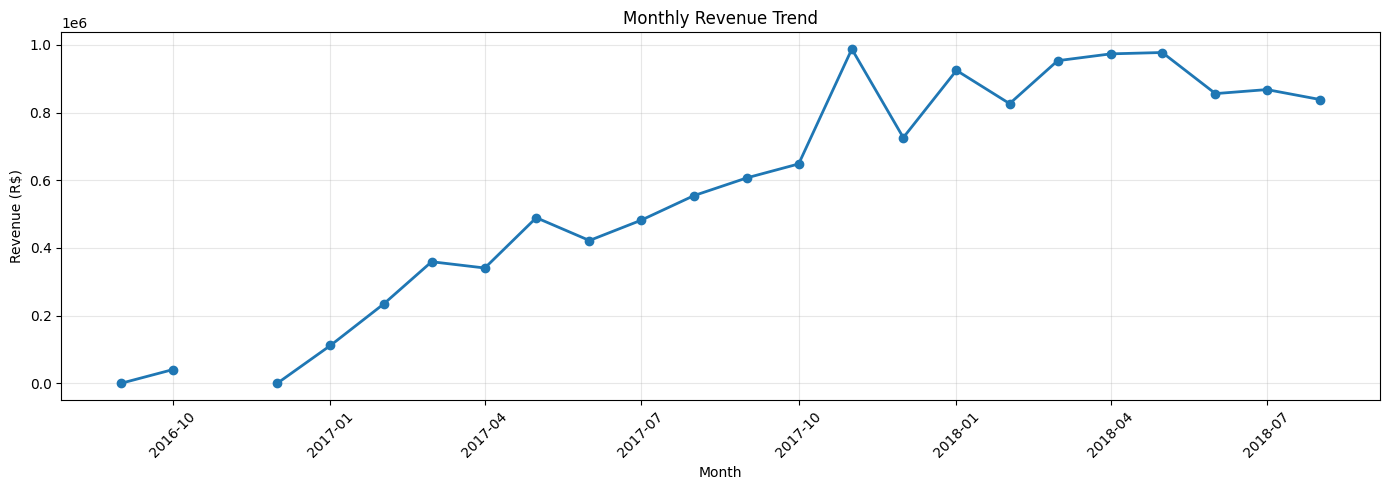

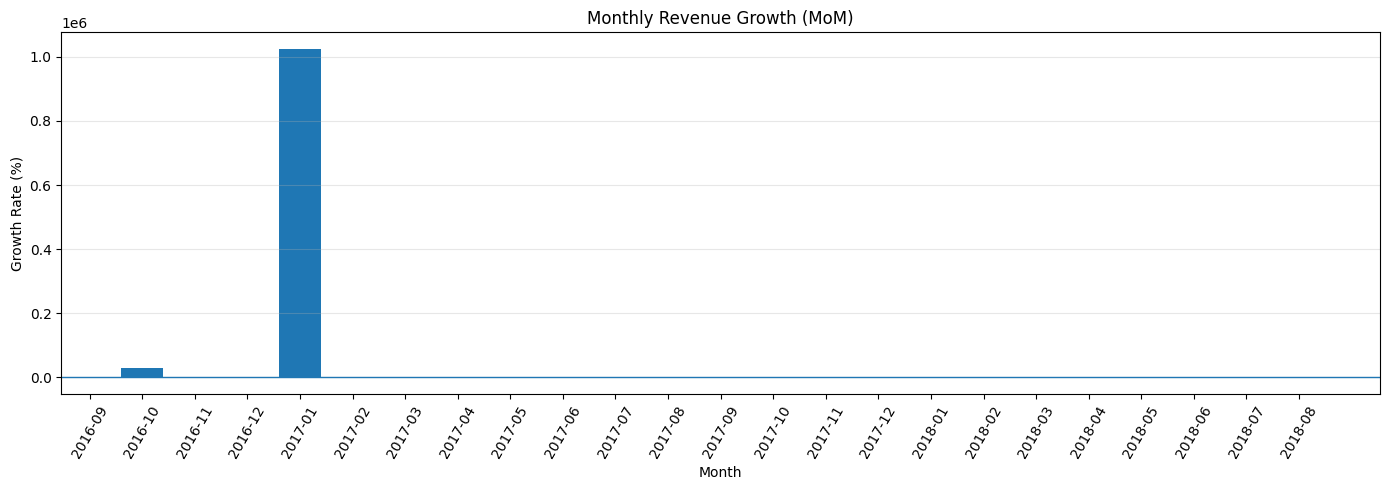

In [17]:
# Revenue trend chart
plt.figure(figsize=(14, 5))

plt.plot(
    monthly_sales_full.index.to_timestamp(),
    monthly_sales_full["total_revenue"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Month-over-month growth chart
plt.figure(figsize=(14, 5))

plt.bar(
    monthly_sales_full.index.astype(str),
    monthly_sales_full["revenue_growth_pct"]
)

plt.axhline(y=0, linewidth=1)
plt.title("Monthly Revenue Growth (MoM)")
plt.xlabel("Month")
plt.ylabel("Growth Rate (%)")
plt.xticks(rotation=60)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [18]:
# Highest and lowest revenue months
print("TOP 5 MONTHS BY REVENUE")

display(
    monthly_sales_full.nlargest(5, "total_revenue")[
        ["total_revenue", "total_orders", "average_order_value"]
    ].round(2)
)

print("\nBOTTOM 5 MONTHS BY REVENUE")

display(
    monthly_sales_full.nsmallest(5, "total_revenue")[
        ["total_revenue", "total_orders", "average_order_value"]
    ].round(2)
)

print("\nHIGHEST MONTH-OVER-MONTH GROWTH")

display(
    monthly_sales_full.nlargest(5, "revenue_growth_pct")[
        ["total_revenue", "revenue_growth_pct"]
    ].round(2)
)

TOP 5 MONTHS BY REVENUE


,total_revenue,total_orders,average_order_value
2017-11,987765.37,7289.0,135.51
2018-05,977544.69,6749.0,144.84
2018-04,973534.09,6798.0,143.21
2018-03,953356.25,7003.0,136.14
2018-01,924645.00,7069.0,130.80



BOTTOM 5 MONTHS BY REVENUE


,total_revenue,total_orders,average_order_value
2016-12,10.90,1.0,10.90
2016-09,134.97,1.0,134.97
2016-10,40325.11,265.0,152.17
2017-01,111798.36,750.0,149.06
2017-02,234223.40,1653.0,141.70



HIGHEST MONTH-OVER-MONTH GROWTH


,total_revenue,revenue_growth_pct
2017-01,111798.36,1025573.03
2016-10,40325.11,29777.09
2017-02,234223.40,109.51
2017-03,359198.85,53.36
2017-11,987765.37,52.37


In [19]:
# Merge delivered orders with order items
category_data = completed_orders[
    ["order_id"]
].merge(
    order_items[["order_id", "product_id", "price"]],
    on="order_id",
    how="inner"
)

# Merge product information
products = datasets["olist_products_dataset"].copy()

category_data = category_data.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# Merge English category translations
translations = datasets[
    "product_category_name_translation"
].copy()

category_data = category_data.merge(
    translations,
    on="product_category_name",
    how="left"
)

# Handle missing category names
category_data["category_english"] = (
    category_data["product_category_name_english"]
    .fillna("Unknown")
)

# Group sales by product category
category_sales = category_data.groupby(
    "category_english"
).agg(
    total_revenue=("price", "sum"),
    total_orders=("order_id", "nunique"),
    total_items=("product_id", "count"),
    average_item_price=("price", "mean")
)

# Sort by revenue
category_sales = category_sales.sort_values(
    "total_revenue",
    ascending=False
)

print("TOP 10 PRODUCT CATEGORIES BY REVENUE")
display(category_sales.head(10).round(2))

print("\nTOP 10 PRODUCT CATEGORIES BY ITEMS SOLD")
display(
    category_sales.sort_values(
        "total_items",
        ascending=False
    ).head(10).round(2)
)

TOP 10 PRODUCT CATEGORIES BY REVENUE


,total_revenue,total_orders,total_items,average_item_price
category_english,,,,
health_beauty,1233131.72,8647,9465,130.28
watches_gifts,1166176.98,5495,5859,199.04
bed_bath_table,1023434.76,9272,10953,93.44
sports_leisure,954852.55,7530,8431,113.25
computers_accessories,888724.61,6530,7644,116.26
furniture_decor,711927.69,6307,8160,87.25
housewares,615628.69,5743,6795,90.60
cool_stuff,610204.10,3559,3718,164.12
auto,578966.65,3810,4140,139.85



TOP 10 PRODUCT CATEGORIES BY ITEMS SOLD


,total_revenue,total_orders,total_items,average_item_price
category_english,,,,
bed_bath_table,1023434.76,9272,10953,93.44
health_beauty,1233131.72,8647,9465,130.28
sports_leisure,954852.55,7530,8431,113.25
furniture_decor,711927.69,6307,8160,87.25
computers_accessories,888724.61,6530,7644,116.26
housewares,615628.69,5743,6795,90.60
watches_gifts,1166176.98,5495,5859,199.04
telephony,309860.23,4093,4430,69.95
garden_tools,470495.28,3448,4268,110.24


In [20]:
# Load payment data
payments = datasets["olist_order_payments_dataset"].copy()

# Keep only delivered orders for consistency with previous analyses
payment_data = payments.merge(
    completed_orders[["order_id"]],
    on="order_id",
    how="inner"
)

# Analyze payment methods
payment_analysis = payment_data.groupby(
    "payment_type"
).agg(
    total_payment_value=("payment_value", "sum"),
    total_orders=("order_id", "nunique"),
    payment_records=("payment_type", "count"),
    average_payment_value=("payment_value", "mean"),
    average_installments=("payment_installments", "mean")
)

# Calculate each payment method's share of total payment value
payment_analysis["revenue_share_pct"] = (
    payment_analysis["total_payment_value"]
    / payment_analysis["total_payment_value"].sum()
) * 100

# Sort by total payment value
payment_analysis = payment_analysis.sort_values(
    "total_payment_value",
    ascending=False
)

print("PAYMENT METHOD ANALYSIS")
display(payment_analysis.round(2))

PAYMENT METHOD ANALYSIS


,total_payment_value,total_orders,payment_records,average_payment_value,average_installments,revenue_share_pct
payment_type,,,,,,
credit_card,12101094.88,74304,74586,162.24,3.5,78.46
boleto,2769932.58,19191,19191,144.33,1.0,17.96
voucher,343013.19,3679,5493,62.45,1.0,2.22
debit_card,208421.12,1485,1486,140.26,1.0,1.35


In [21]:
# Load review data
reviews = datasets["olist_order_reviews_dataset"].copy()

# Keep reviews linked to delivered orders
review_data = reviews.merge(
    completed_orders[["order_id"]],
    on="order_id",
    how="inner"
)

# Review score distribution
review_distribution = review_data["review_score"].value_counts(
    normalize=False
).sort_index()

# Calculate percentages
review_percentages = (
    review_data["review_score"].value_counts(
        normalize=True
    ).sort_index() * 100
)

# Combine results
review_analysis = pd.DataFrame({
    "review_count": review_distribution,
    "percentage": review_percentages
})

print("CUSTOMER REVIEW DISTRIBUTION")
display(review_analysis.round(2))

# Overall review metrics
print("\nOVERALL REVIEW METRICS")

print("Total Reviews:", len(review_data))
print("Average Review Score:", round(
    review_data["review_score"].mean(), 2
))

print("Positive Reviews (4-5):", round(
    review_data["review_score"].isin([4, 5]).mean() * 100, 2
), "%")

print("Negative Reviews (1-2):", round(
    review_data["review_score"].isin([1, 2]).mean() * 100, 2
), "%")

CUSTOMER REVIEW DISTRIBUTION


,review_count,percentage
review_score,,
1,9406,9.76
2,2941,3.05
3,7961,8.26
4,18987,19.70
5,57066,59.22



OVERALL REVIEW METRICS
Total Reviews: 96361
Average Review Score: 4.16
Positive Reviews (4-5): 78.93 %
Negative Reviews (1-2): 12.81 %


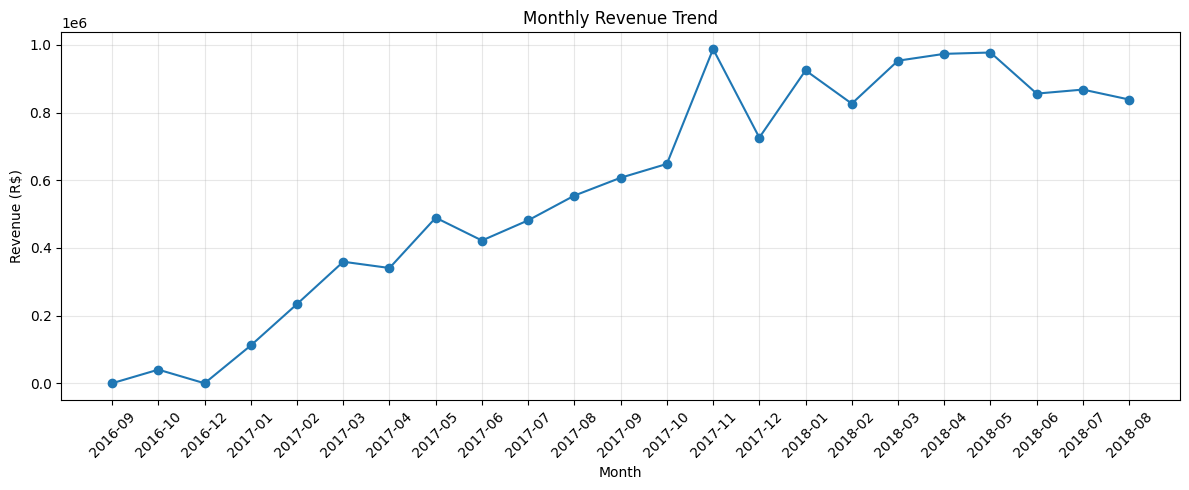

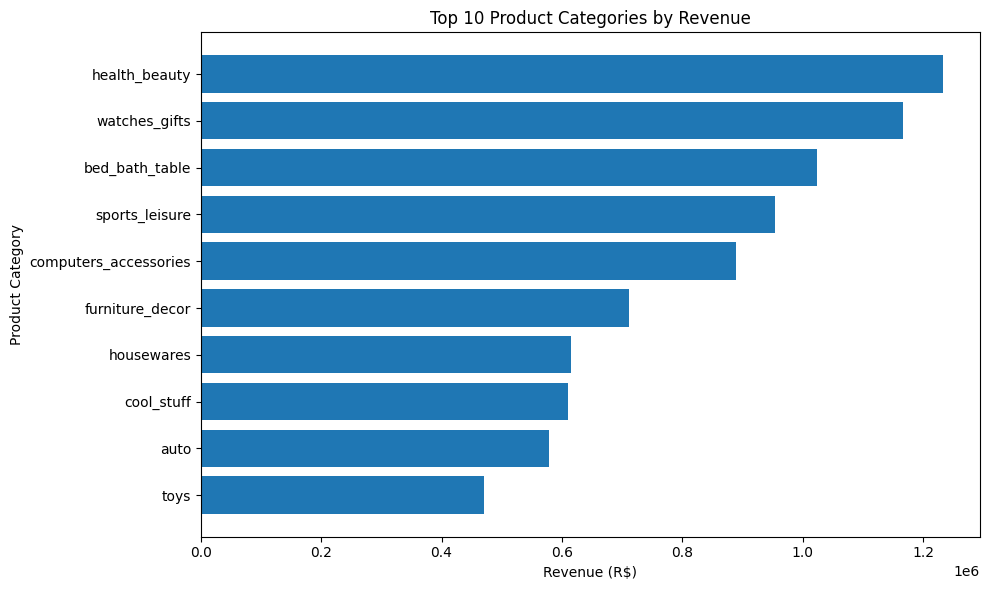

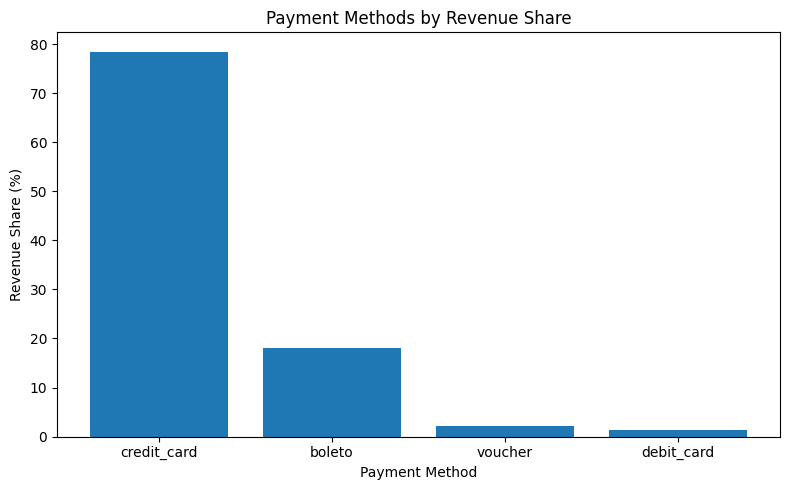

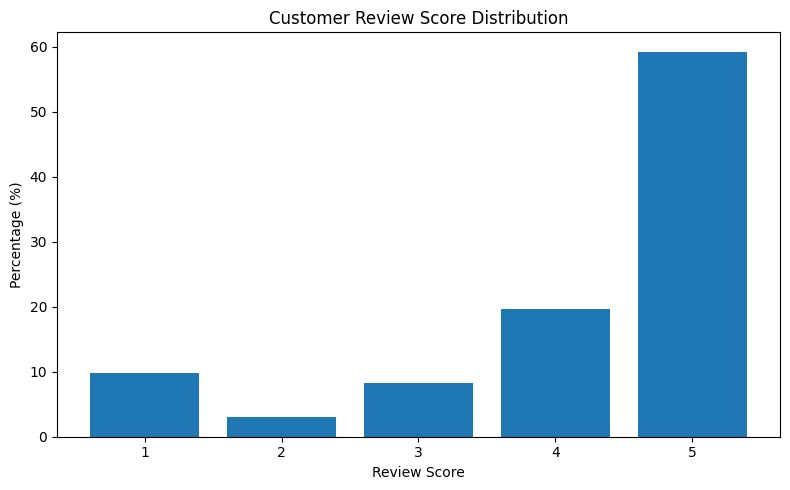

In [22]:
import matplotlib.pyplot as plt

# 1. Monthly Revenue Trend
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales["total_revenue"],
    marker="o"
)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (R$)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Top 10 Categories by Revenue
top_categories = category_sales.head(10).sort_values(
    "total_revenue"
)

plt.figure(figsize=(10, 6))
plt.barh(
    top_categories.index,
    top_categories["total_revenue"]
)
plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (R$)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


# 3. Payment Method Distribution
plt.figure(figsize=(8, 5))
plt.bar(
    payment_analysis.index,
    payment_analysis["revenue_share_pct"]
)
plt.title("Payment Methods by Revenue Share")
plt.xlabel("Payment Method")
plt.ylabel("Revenue Share (%)")
plt.tight_layout()
plt.show()


# 4. Customer Review Distribution
plt.figure(figsize=(8, 5))
plt.bar(
    review_analysis.index.astype(str),
    review_analysis["percentage"]
)
plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

# Final Business Insights

## 1. Sales Performance
- Total revenue from delivered orders reached 13.22 million BRL.
- A total of 96,478 delivered orders were analyzed.
- The average order value was 137.04 BRL.
- November 2017 recorded the highest monthly revenue at 987,765.37 BRL.

## 2. Product Category Performance
- Health & Beauty generated the highest revenue at 1.23 million BRL.
- Watches & Gifts ranked second, with 1.17 million BRL in revenue.
- Bed, Bath & Table recorded the highest number of order items (10,953).

## 3. Payment Methods
- Credit cards accounted for 78.46% of total payment value.
- Boleto represented 17.96%.
- Credit card payments had an average of 3.5 installments.

## 4. Customer Reviews
- The average customer review score was 4.16 out of 5.
- Positive reviews (4–5 stars) represented 78.93%.
- Negative reviews (1–2 stars) represented 12.81%.

## 5. Delivery Performance
- Average delivery time was 12.56 days.
- 91.89% of analyzed orders arrived on or before the estimated delivery date.
- 8.11% of orders were delivered late.
- A small number of orders experienced exceptionally long delivery delays.

# Business Recommendations

1. **Improve Delivery Performance:** Investigate exceptionally delayed shipments and monitor shipping partners to reduce late deliveries.

2. **Focus on High-Revenue Categories:** Maintain strong inventory and marketing strategies for Health & Beauty and Watches & Gifts.

3. **Optimize Product Strategy:** Investigate why some categories generate high sales volumes but relatively lower revenue per item.

4. **Improve Payment Experience:** Maintain a reliable credit card payment experience while exploring ways to encourage the use of other payment methods.

5. **Improve Customer Satisfaction:** Investigate negative reviews and identify whether delivery delays, product quality, or other factors contribute to customer dissatisfaction.

# Project Limitations

- The analysis focuses on delivered orders only, excluding canceled and other non-delivered orders.
- The dataset covers a historical period from 2016 to 2018, so the findings may not reflect current e-commerce trends.
- Missing values in some columns may affect certain analyses.
- The dataset does not provide enough information to identify the exact causes of delivery delays or negative customer reviews.
- Revenue calculations are based on product prices and exclude shipping fees.
- The dataset represents one Brazilian e-commerce platform and may not reflect the entire Brazilian e-commerce market.